# Tugas Praktikum JS06 - Multiple Linear Regression & SVR pada Medical Cost Personal Datasets

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## 1. Pemahaman Dataset dan Identifikasi Variabel (`insurance.csv`)

Dataset **Medical Cost Personal Datasets** (`insurance.csv`) berisi `1.338` data rekam profil nasabah asuransi kesehatan di Amerika Serikat beserta besaran tagihan biaya medis tahunan yang ditanggung asuransi. Rincian ketujuh variabel di dalam dataset ini adalah:

- **Variabel Bebas / Fitur ($X$):**
  1. `age` (*numerik - integer*): Usia penerima manfaat utama asuransi (`18` s.d. `64` tahun).
  2. `sex` (*kategorikal*): Jenis kelamin nasabah (`female` atau `male`).
  3. `bmi` (*numerik - float*): *Body Mass Index* (indeks massa tubuh dalam $\text{kg/m}^2$, rentang ideal `18.5` s.d. `24.9`).
  4. `children` (*numerik - integer*): Jumlah anak atau tanggungan yang tercakup dalam polis asuransi (`0` s.d. `5` anak).
  5. `smoker` (*kategorikal*): Status apakah nasabah merokok secara aktif (`yes` atau `no`).
  6. `region` (*kategorikal*): Area tempat tinggal nasabah di Amerika Serikat (`northeast`, `northwest`, `southeast`, `southwest`).
- **Variabel Target / Dependen ($y$):**
  7. `charges` (*numerik - float*): Biaya medis personal yang ditagihkan kepada asuransi kesehatan (dalam satuan Dolar AS).

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset insurance.csv
df = pd.read_csv('insurance.csv')
print(f"Ukuran dataset: {df.shape[0]} baris dan {df.shape[1]} kolom\n")
df.info()
df.head()

Ukuran dataset: 1338 baris dan 7 kolom

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
# Statistik deskriptif kolom numerik dan pengecekan missing values
print("Jumlah nilai kosong (NaN) per kolom:")
print(df.isnull().sum())
df.describe()

Jumlah nilai kosong (NaN) per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Dari hasil inspeksi di atas, seluruh `1.338` baris terisi lengkap tanpa adanya *missing value* (`0` nilai kosong). Rata-rata usia nasabah adalah `39.21` tahun, rata-rata `bmi` sebesar `30.66`, dan rata-rata biaya medis `charges` adalah `$13,270.42` dengan simpangan baku yang cukup besar yaitu `$12,110.01` (rentang dari `$1,121.87` hingga `$63,770.43`).

## 2. Pra-pengolahan Data (Encoding Variabel Kategorikal) & Visualisasi Eksploratif

Karena terdapat tiga fitur kategorikal bertipe teks (`sex`, `smoker`, dan `region`), ketiganya diubah terlebih dahulu menjadi representasi numerik menggunakan `LabelEncoder`. Setelah itu saya menampilkan visualisasi matriks korelasi *heatmap* serta *scatter plot* hubungan antara `age`, `bmi`, dan status `smoker` terhadap `charges`.

In [3]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()
categorical_cols = ['sex', 'smoker', 'region']
encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    encoders[col] = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"Mapping {col}: {encoders[col]}")

df_encoded.head()

Mapping sex: {'female': np.int64(0), 'male': np.int64(1)}
Mapping smoker: {'no': np.int64(0), 'yes': np.int64(1)}
Mapping region: {'northeast': np.int64(0), 'northwest': np.int64(1), 'southeast': np.int64(2), 'southwest': np.int64(3)}


,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520


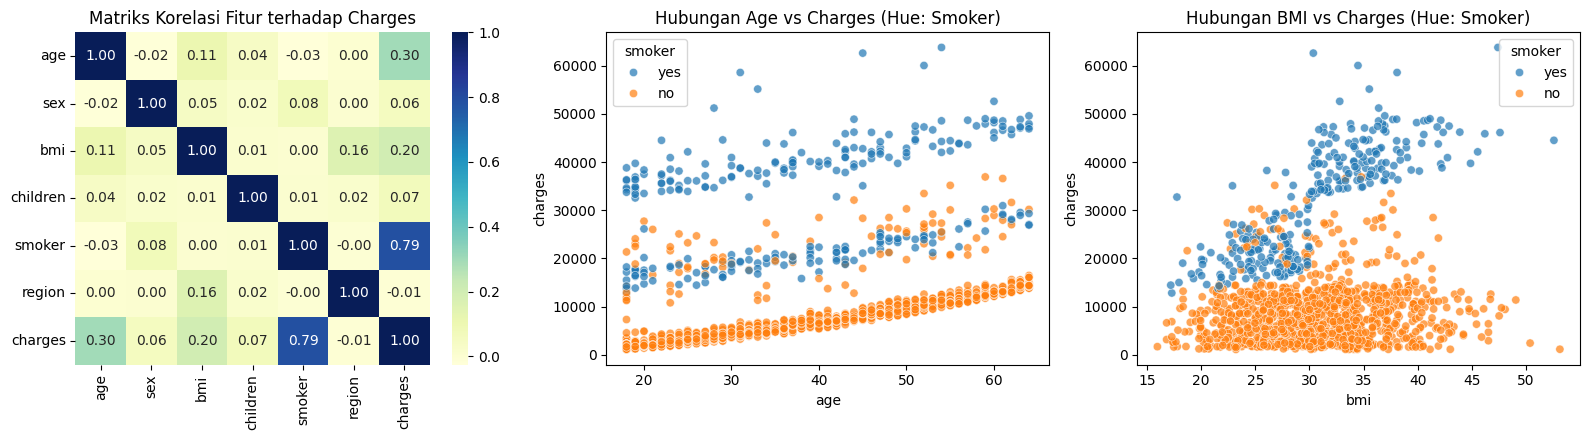

In [4]:
# Visualisasi Heatmap Korelasi dan Scatter Plot Faktor Utama terhadap Charges
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Heatmap korelasi
sns.heatmap(df_encoded.corr(), annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[0])
axes[0].set_title('Matriks Korelasi Fitur terhadap Charges')

# 2. Scatter plot Age vs Charges berdasarkan status Smoker
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7, ax=axes[1])
axes[1].set_title('Hubungan Age vs Charges (Hue: Smoker)')

# 3. Scatter plot BMI vs Charges berdasarkan status Smoker
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=axes[2])
axes[2].set_title('Hubungan BMI vs Charges (Hue: Smoker)')

plt.tight_layout()
plt.show()

Dari ketiga grafik di atas terlihat pola yang sangat menarik:

1. **Korelasi Dominan `smoker` (`r = 0.79`):** Variabel `smoker` memiliki korelasi positif paling tinggi terhadap `charges` (`0.79`), disusul oleh `age` (`0.30`) dan `bmi` (`0.20`). Sementara itu, `children` (`0.07`), `sex` (`0.06`), dan `region` (`-0.01`) memiliki korelasi linier langsung yang sangat kecil.
2. **Efek Interaksi `bmi` dan `smoker`:** Pada grafik kedua (`Age vs Charges`), biaya medis meningkat secara linier seiring bertambahnya usia dalam tiga pita sejajar, di mana pita nasabah bukan perokok (`smoker = no`) berada di lapisan paling bawah (`<$15,000`). Pada grafik ketiga (`BMI vs Charges`), terlihat bahwa bagi nasabah perokok (`smoker = yes`), ketika nilai `bmi` melewati angka `30` (kategori obesitas), tagihan biaya medis melonjak drastis dari kisaran `$20,000` ke atas `$35,000 - $63,000`.

## 3. Pembagian Data (Train-Test Split 80:20) dan Feature Scaling

Seluruh 6 fitur (`age`, `sex`, `bmi`, `children`, `smoker`, `region`) dipisahkan sebagai matriks fitur `X` dan kolom `charges` sebagai vektor target `y`. Dataset dibagi dengan proporsi **80% data latih (`1.070` baris)** dan **20% data uji (`268` baris)** menggunakan `random_state = 42`. Selanjutnya dilakukan *feature scaling* menggunakan `StandardScaler` agar fitur dengan satuan puluhan (`age`, `bmi`) dan fitur biner/kategorikal (`smoker`, `sex`, `region`) berada pada skala distribusi standar yang setara.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Ukuran X_train: {X_train.shape}, Ukuran X_test: {X_test.shape}")

# Feature Scaling pada variabel bebas X
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

pd.DataFrame(X_train_scaled, columns=X.columns).head()

Ukuran X_train: (1070, 6), Ukuran X_test: (268, 6)


,age,sex,bmi,children,smoker,region
0,0.472227,-1.024602,-1.756525,0.734336,-0.508747,-0.456116
1,0.543313,-1.024602,-1.033082,-0.911192,-0.508747,-1.353256
2,0.898745,-1.024602,-0.943687,-0.911192,-0.508747,0.441024
3,-0.025379,-1.024602,0.622393,3.202629,-0.508747,0.441024
4,1.040918,-1.024602,-1.504893,1.557100,-0.508747,-0.456116


## 4. Pemodelan Multiple Linear Regression dan Evaluasi Model

Melatih model `LinearRegression` dari `scikit-learn` pada data latih (`X_train_scaled`, `y_train`), melakukan prediksi pada data uji (`X_test_scaled`), serta menghitung metrik evaluasi **R-squared ($R^2$)**, **MSE**, **RMSE**, dan **MAE**.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Inisialisasi dan pelatihan model Multiple Linear Regression
mlr_model = LinearRegression()
mlr_model.fit(X_train_scaled, y_train)

# Prediksi pada data latih dan data uji
y_train_pred_mlr = mlr_model.predict(X_train_scaled)
y_test_pred_mlr = mlr_model.predict(X_test_scaled)

# Evaluasi metrik pada data uji
r2_train_mlr = r2_score(y_train, y_train_pred_mlr)
r2_test_mlr = r2_score(y_test, y_test_pred_mlr)
mse_mlr = mean_squared_error(y_test, y_test_pred_mlr)
rmse_mlr = np.sqrt(mse_mlr)
mae_mlr = mean_absolute_error(y_test, y_test_pred_mlr)

print("=== Hasil Evaluasi Multiple Linear Regression ===")
print(f"R-squared (Data Latih) : {r2_train_mlr:.4f}")
print(f"R-squared (Data Uji)   : {r2_test_mlr:.4f}")
print(f"Mean Squared Error     : {mse_mlr:,.2f}")
print(f"Root Mean Squared Error: ${rmse_mlr:,.2f}")
print(f"Mean Absolute Error    : ${mae_mlr:,.2f}\n")

# Menampilkan intercept dan koefisien masing-masing fitur
df_coef = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien (Terstandardisasi)': np.round(mlr_model.coef_, 4)
}).sort_values(by='Koefisien (Terstandardisasi)', ascending=False)
print(f"Intercept (beta_0): {mlr_model.intercept_:.4f}")
df_coef

=== Hasil Evaluasi Multiple Linear Regression ===
R-squared (Data Latih) : 0.7417
R-squared (Data Uji)   : 0.7833
Mean Squared Error     : 33,635,210.43
Root Mean Squared Error: $5,799.59
Mean Absolute Error    : $4,186.51

Intercept (beta_0): 13346.0897


,Fitur,Koefisien (Terstandardisasi)
4,smoker,9557.1434
0,age,3616.1087
2,bmi,2028.3086
3,children,516.6626
1,sex,-9.3930
5,region,-302.3880


## 5. Perbandingan dengan Support Vector Regression (SVR) & Visualisasi Hasil Prediksi

Sesuai instruksi umum modul untuk menganalisis regresi linier maupun SVR, saya juga melatih model **Support Vector Regression (`SVR(kernel='rbf')`)** pada data yang sama untuk melihat apakah kernel non-linier RBF mampu menangkap lonjakan biaya medis pada perokok dengan BMI tinggi secara lebih akurat.

In [7]:
from sklearn.svm import SVR

# Scaling variabel target y khusus untuk SVR
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()

svr_model = SVR(kernel='rbf', C=10.0, epsilon=0.1)
svr_model.fit(X_train_scaled, y_train_scaled)

# Prediksi SVR pada data uji dan inverse transform ke satuan Dolar
y_test_pred_svr_sc = svr_model.predict(X_test_scaled)
y_test_pred_svr = scaler_y.inverse_transform(y_test_pred_svr_sc.reshape(-1, 1)).ravel()

r2_test_svr = r2_score(y_test, y_test_pred_svr)
mse_svr = mean_squared_error(y_test, y_test_pred_svr)
rmse_svr = np.sqrt(mse_svr)
mae_svr = mean_absolute_error(y_test, y_test_pred_svr)

df_eval_summary = pd.DataFrame([
    {
        'Model': 'Multiple Linear Regression',
        'R-squared (R2)': round(r2_test_mlr, 4),
        'MAE ($)': round(mae_mlr, 2),
        'MSE': round(mse_mlr, 2),
        'RMSE ($)': round(rmse_mlr, 2)
    },
    {
        'Model': 'SVR (kernel=RBF, C=10)',
        'R-squared (R2)': round(r2_test_svr, 4),
        'MAE ($)': round(mae_svr, 2),
        'MSE': round(mse_svr, 2),
        'RMSE ($)': round(rmse_svr, 2)
    }
])
df_eval_summary

,Model,R-squared (R2),MAE ($),MSE,RMSE ($)
0,Multiple Linear Regression,0.7833,4186.51,33635210.43,5799.59
1,"SVR (kernel=RBF, C=10)",0.8693,2346.96,20296090.75,4505.12


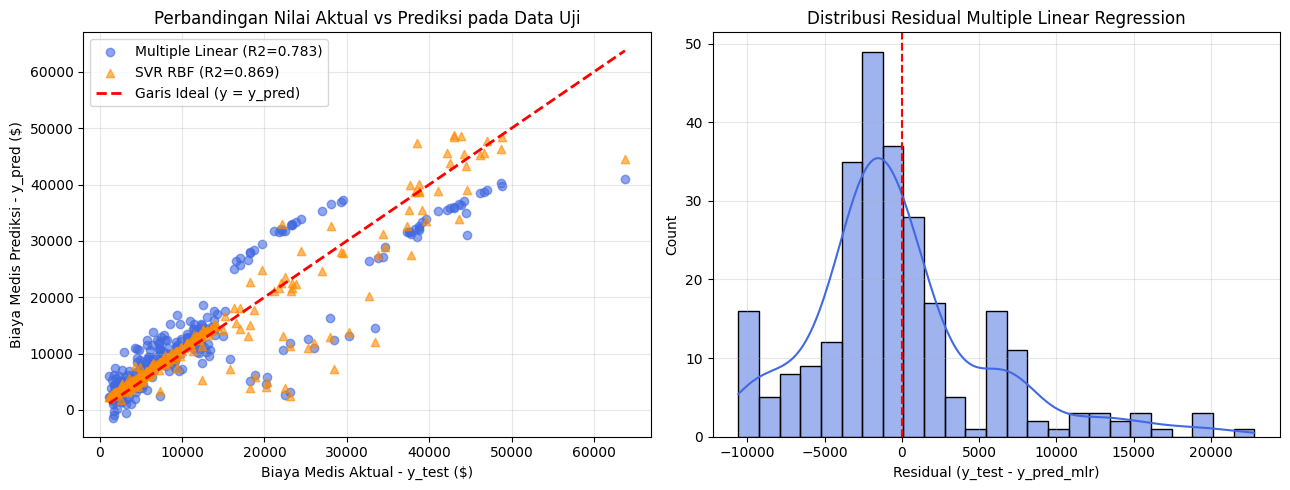

In [8]:
# Visualisasi Nilai Aktual vs Nilai Prediksi serta Distribusi Residual
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Actual vs Predicted (Multiple Linear Regression vs SVR)
axes[0].scatter(y_test, y_test_pred_mlr, alpha=0.6, color='royalblue', label=f'Multiple Linear (R2={r2_test_mlr:.3f})')
axes[0].scatter(y_test, y_test_pred_svr, alpha=0.6, color='darkorange', marker='^', label=f'SVR RBF (R2={r2_test_svr:.3f})')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Ideal (y = y_pred)')
axes[0].set_xlabel('Biaya Medis Aktual - y_test ($)')
axes[0].set_ylabel('Biaya Medis Prediksi - y_pred ($)')
axes[0].set_title('Perbandingan Nilai Aktual vs Prediksi pada Data Uji')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Distribusi Residual Multiple Linear Regression
residuals_mlr = y_test - y_test_pred_mlr
sns.histplot(residuals_mlr, kde=True, bins=25, color='royalblue', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', lw=1.5)
axes[1].set_xlabel('Residual (y_test - y_pred_mlr)')
axes[1].set_title('Distribusi Residual Multiple Linear Regression')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Analisis Hasil Tugas Praktikum

Berdasarkan seluruh tahapan eksperimen pada dataset `insurance.csv` di atas, diperoleh beberapa kesimpulan penting:

1. **Kontribusi Fitur pada Multiple Linear Regression:** Dari nilai koefisien regresi terstandardisasi (`mlr_model.coef_`), faktor yang paling menentukan kenaikan biaya medis tahunan adalah status merokok **`smoker` (`+$9,557.14` per satu simpangan baku)**, diikuti oleh usia **`age` (`+$3,616.11`)**, indeks massa tubuh **`bmi` (`+$2,028.31`)**, dan jumlah anak **`children` (`+$516.66`)**. Sementara itu, jenis kelamin `sex` (`-$9.39`) dan wilayah `region` (`-$302.39`) memberikan pengaruh yang sangat kecil terhadap biaya tagihan medis.
2. **Kinerja dan Kestabilan Multiple Linear Regression:** Model **Multiple Linear Regression** menghasilkan nilai **$R^2$ pada data uji sebesar `0.7833` (`78.33%`)**, yang bahkan sedikit lebih tinggi dan sangat konsisten terhadap $R^2$ pada data latih (`0.7417`). Nilai **MAE** sebesar **`$4,186.51`** dan **RMSE** sebesar **`$5,799.59`** menunjukkan bahwa rata-rata penyimpangan prediksi model linier berada di kisaran `$4.186` dari tagihan sebenarnya.
3. **Keunggulan Non-Linier SVR (`kernel='rbf'`):** Ketika diuji menggunakan **SVR ber-kernel RBF**, skor **$R^2$ pada data uji meningkat menjadi `0.8693` (`86.93%`)**, sementara **MAE turun hampir separuhnya menjadi `$2,346.96`** dan **RMSE turun menjadi `$4,505.12`**. Sebagaimana terlihat pada *scatter plot* `Aktual vs Prediksi`, titik-titik oranye (`SVR RBF`) jauh lebih menempel ke garis diagonal merah ideal dibandingkan titik-titik biru (`Multiple Linear Regression`), karena kernel RBF mampu menangkap efek interaksi non-linier antara kebiasaan merokok (`smoker = yes`) dan obesitas (`bmi > 30`) yang tidak dapat direpresentasikan oleh penjumlahan linier biasa.